###  
1. load a model 
2. predict on test set
3. compute metrics from available datasets (e.g. MapBiomas)
    - probably per-dataset
    
4. later, add multiple models and get some notion of variance 

In [9]:
import os
import json

import geopandas as gpd
import pandas as pd
import wandb
import torch
import torch.nn as nn
import torch.nn.functional as F
import tqdm 

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from shapely.geometry import Polygon

import sys
sys.path.append('../')
from model.model import MultiModalDriverClassifier
import model.dataloader as dataloader

from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]
from sklearn.metrics import confusion_matrix, classification_report


In [3]:

LABEL_MAPPING = {
    'pasture' : 0, 
    'forest plantation' : 1,
    'soy' : 2,
    'coffee' : 3,
    'palm oil': 4,
    'mining': 5,
    'urban': 6,
    'cocoa': 7,
    'rubber': 8,
    'shifting agriculture': 9,
    'other': 10 
}

inv_label_mapping = {v:k for k,v in LABEL_MAPPING.items()}

In [118]:
# List of trained models used to predict
wandb_ids = [
    'fuvmj0ci',  #img+loc+tab
    'l432djh6', #img+loc
    'ljpkbdnc', #img+loc+tab
    '9iotpknc', #img+loc
    'gnzo519j', #img
    '5o0zfbth', #img
    ]

#img_only = 'wyfrp4uy'

device = 'cuda'


wandb_ids = ['9h2pydld'] # has some location noise added
wandb_ids = ['687oxezs'] #should be close to project_2 models
wandb_ids = ['g6j5p6si'] #0.05 loc dropout 
wandb_ids = ['rm59w2o0'] #0.2 loc dropout 




In [114]:
path_to_images = '/home/jan/Documents/EPFL/Picterra/localito/data/images/inference_2021'
path_to_annotation = '/home/jan/Documents/EPFL/Picterra/localito/data/misc/inference_with_labels_2021_labeled.csv'
path_to_forestloss = '/home/jan/Documents/EPFL/Picterra/localito/data/forestloss_patches/inference_2021/'

In [115]:



def add_country_names(gdf, countries=tropical_countries, country_name_mapping=country_name_mapping):

    gdf = gpd.sjoin(gdf, countries[['geometry', 'name']], how='left', predicate='within')[['geometry', 'driver', 'sampleid', 'dataset', 'name']]
    gdf['country'] = gdf['name']
    gdf = gdf.drop('name', axis=1)


    names_to_edit = [key for key in country_name_mapping.keys()]
    for name in names_to_edit:
        gdf.loc[gdf['country'] == name, 'country'] = country_name_mapping[name]

    return gdf

def find_intersections_or_nearest(gdf_points, gdf_polygons):
    from shapely.ops import nearest_points

    """
    For each point in gdf_points, find which polygon it intersects with. 
    If it doesn't intersect any polygon, find the closest polygon.
    
    Parameters:
    gdf_points (GeoDataFrame): A GeoDataFrame containing points.
    gdf_polygons (GeoDataFrame): A GeoDataFrame containing polygons.
    
    Returns:
    GeoDataFrame: A GeoDataFrame of points with a new column 'nearest_or_intersecting_polygon' indicating the index of the intersecting or nearest polygon.
    """
    # Initialize a column to store the index of the nearest or intersecting polygon
    gdf_points['country'] = None
    
    for point_index, point_row in gdf_points.iterrows():
        # Check for intersections first
        intersects = gdf_polygons.intersects(point_row.geometry)
        if intersects.any():
            # If there's an intersection, use the first intersecting polygon
            idx = intersects.idxmax()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[idx]['name']
        else:
            # Find the nearest polygon if no intersection
            # Calculate the nearest points between the current point and all polygons, then find the minimum
            distances = gdf_polygons.geometry.apply(lambda poly: point_row.geometry.distance(nearest_points(point_row.geometry, poly)[1]))
            nearest_polygon_index = distances.idxmin()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[nearest_polygon_index]['name']
    
    return gdf_points


In [34]:
country_name_mapping = {
    "Vietnam" : "Viet Nam",
    "Tanzania" : "United Republic of Tanzania",
    "Dem. Rep. Congo" : "Democratic Republic of the Congo",
    "Dominican Rep." : "Dominican Republic",
    "Bolivia" : "Bolivia (Plurinational State of)",
    "Venezuela" : "Venezuela (Bolivarian Republic of)",
    "Central African Rep.": "Central African Republic",
    "Eq. Guinea" : "Equatorial Guinea",
    "eSwatini" : "Eswatini",
    "Laos" : "Lao People's Democratic Republic",
    "Taiwan" : "China, Taiwan Province of",
    "Brunei" : "Brunei Darussalam",
    "S. Sudan" : "South Sudan",
    "Solomon Is." : "Solomon Islands"
}

#Add country name
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

min_lon = -180
max_lon = 180
min_lat = -30
max_lat = 30
tropics = Polygon([(min_lon, min_lat), (min_lon, max_lat), (max_lon, max_lat, ), (max_lon, min_lat )])
tropical_countries = world.loc[world.intersects(tropics)].reset_index(drop=True)


/tmp/ipykernel_199968/1944021917.py:19: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


In [35]:
df = pd.read_csv(path_to_annotation)


/tmp/ipykernel_199968/1612969104.py:1: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path_to_annotation)


In [36]:
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
gdf = gpd.GeoDataFrame(df)
gdf.crs = 4326

In [38]:
gdf = add_country_names(gdf)
nearest_countries = find_intersections_or_nearest(gdf.loc[gdf.country.isna()], tropical_countries)
gdf.loc[gdf.country.isna(), 'country'] = nearest_countries['country']
df_with_countries = pd.DataFrame(gdf)
df['country'] = df_with_countries['country']

In [60]:
#gdf.loc[gdf.country.isna()].dataset.value_counts()

In [61]:
df.to_csv(path_to_annotation, index=False)

'/home/jan/Documents/EPFL/Picterra/localito/data/misc/inference_with_labels_2021_labeled.csv'

In [121]:
results = {}

for _id in wandb_ids:
    print(_id)
    
    results[_id] = {}
    
    try:
        model_dir = f'/home/jan/Documents/EPFL/Picterra/localito/models_trained/{_id}'    
    
        config_path = os.path.join(model_dir, 'config.json')
        with open(config_path) as source:
            config = json.loads(source.read())
    except FileNotFoundError:
        model_dir = f'/home/jan/Documents/EPFL/project_2/models_trained/{_id}'    
        config_path = os.path.join(model_dir, 'config.json')
        with open(config_path) as source:
            config = json.loads(source.read())
    
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
        
    config['hyperparams']['folds_to_split']['mapping'] = {'99' : 'test'}
    config['wandb']['log_to_wandb'] = False 
        
    config['data']['annotation_file'] = path_to_annotation
    config['data']['image_folder'] = path_to_images
    config['data']['forestloss_folder'] = path_to_forestloss
    
    config['hyperparams']['use_forestloss'] = True
    config['hyperparams']['model_version'] = 'v1'
    config['hyperparams']['tabular_encoder'] =  {
                "use" : False,
                "dataset" : "deduce",
                "type" : "token",
                "temporal_processing" : "dynamic"

            }   

    
    #Load trained model
    model = MultiModalDriverClassifier(11,  **config)
    model = model.to(device)

    trained_model_path = f'{model_dir}/last.pt'
    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()


    # fetch dataloaders
    test_dataloader = dataloader.fetch_dataloader(
        ['test'], config)['test']
    
    
    all_preds = torch.tensor([]).to(device)
    with torch.no_grad():
        for input_batch, _ in tqdm.tqdm(test_dataloader):
            
            image_batch, loc_batch, tab_batch, forestloss_batch = input_batch[0].to(device), input_batch[1].to(device), input_batch[2].to(device), input_batch[3].to(device)
            batch_preds = model(image_batch, loc_batch, tab_batch, forestloss_batch)
            all_preds = torch.cat((all_preds, batch_preds))


    class_preds = F.softmax(all_preds, dim=1).argmax(dim=1).cpu().numpy()
    
    df[_id] = class_preds
    df[_id] = df[_id].map(inv_label_mapping)
    
 

            

rm59w2o0


/home/jan/Documents/EPFL/project_2/notebooks/../model/dataloader.py:193: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12) have mixed types. Specify dtype option on import or set low_memory=False.
  annotation = pd.read_csv(config['data']['annotation_file'])
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3521/3521 [03:37<00:00, 16.19it/s]


In [120]:
image_batch.shape

torch.Size([64, 4, 4, 100, 100])

In [71]:
df.to_csv('../data/tmp/picterra_2021_inference.csv', index=False)

In [81]:
df

,geometry,mines,rubber,palm_oil_2021,masolele_africa,mapbiomas_venezuela,mapbiomas_brasil,cotedivoire,cocoa,mapbiomas_indonesia,...,sampleid,split,driver,country,fuvmj0ci,l432djh6,ljpkbdnc,9iotpknc,gnzo519j,5o0zfbth
0,POINT (-75.56696 20.63668),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,311024007838,99,mining,Cuba,mining,mining,mining,mining,mining,mining
1,POINT (-74.90885 20.62779),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,311024007842,99,mining,Cuba,mining,mining,mining,mining,mining,mining
2,POINT (-75.54917 20.61890),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,311024007845,99,mining,Cuba,mining,mining,mining,mining,mining,rubber
3,POINT (-74.86438 20.61000),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,311024007850,99,mining,Cuba,mining,mining,mining,mining,mining,mining
4,POINT (-74.92664 20.60111),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,311024007857,99,mining,Cuba,mining,mining,mining,mining,mining,mining
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225330,POINT (-52.49849 -32.61895),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,311025248035,99,forest plantation,Brazil,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation
225331,POINT (-52.48960 -32.61895),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,311025248036,99,forest plantation,Brazil,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation
225332,POINT (-52.55185 -32.87686),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,311025248063,99,forest plantation,Brazil,forest plantation,forest plantation,other,other,forest plantation,other
225333,POINT (-52.53406 -32.87686),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,311025248064,99,forest plantation,Brazil,forest plantation,soy,forest plantation,soy,forest plantation,palm oil


## Evaluation

In [72]:
def plot_confusion_matrix(y_true, y_pred, labels=CLASS_NAMES, target_names=None, figsize=(10,10)):
    """
    Generate matrix plot of confusion matrix with pretty annotations.
    args: 
      y_true:    true label of the data, with shape (nsamples,)
      y_pred:    prediction of the data, with shape (nsamples,)
      classes:    string array, name the order of class labels in the confusion matrix.
                 use `clf.classes_` if using scikit-learn models.
                 with shape (nclass,).
      class_names:      dict: any -> string, length == nclass.
                 if not None, map the labels & ys to more understandable strings.
                 Caution: original y_true, y_pred and labels must align.
      figsize:   the size of the figure plotted.
    """
    if target_names is not None:
        y_pred = [target_names[yi] for yi in y_pred]
        y_true = [target_names[yi] for yi in y_true]
        labels = [target_names[yi] for yi in labels]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_sum = np.sum(cm, axis=1, keepdims=True)
    cm_perc = cm / cm_sum.astype(float) * 100
    annot = np.empty_like(cm).astype(str)
    nrows, ncols = cm.shape
    for i in range(nrows):
        for j in range(ncols):
            c = cm[i, j]
            p = cm_perc[i, j]
            if i == j:
                s = cm_sum[i]
                annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)
            elif c == 0:
                annot[i, j] = ''
            else:
                annot[i, j] = '%.1f%%\n%d' % (p, c)
    cm = pd.DataFrame(cm, index=labels, columns=labels)
    cm.index.name = 'Actual'
    cm.columns.name = 'Predicted'
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(cm, annot=annot, fmt='', ax=ax)
    #plt.savefig(filename)
    #plt.tight_layout()
    #plt.close()

    #return filename

In [126]:
df

,geometry,mines,rubber,palm_oil_2021,masolele_africa,mapbiomas_venezuela,mapbiomas_brasil,cotedivoire,cocoa,mapbiomas_indonesia,...,fuvmj0ci,l432djh6,ljpkbdnc,9iotpknc,gnzo519j,5o0zfbth,9h2pydld,687oxezs,g6j5p6si,rm59w2o0
0,POINT (-75.56696 20.63668),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,mining,mining,mining,mining,mining,mining,mining,mining,mining,mining
1,POINT (-74.90885 20.62779),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,mining,mining,mining,mining,mining,mining,mining,mining,mining,mining
2,POINT (-75.54917 20.61890),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,mining,mining,mining,mining,mining,rubber,mining,mining,mining,mining
3,POINT (-74.86438 20.61000),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,mining,mining,mining,mining,mining,mining,mining,mining,mining,mining
4,POINT (-74.92664 20.60111),mining,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,mining,mining,mining,mining,mining,mining,mining,mining,mining,mining
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225330,POINT (-52.49849 -32.61895),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation
225331,POINT (-52.48960 -32.61895),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation,forest plantation
225332,POINT (-52.55185 -32.87686),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,forest plantation,forest plantation,other,other,forest plantation,other,other,other,pasture,other
225333,POINT (-52.53406 -32.87686),NaN,NaN,NaN,NaN,NaN,forest plantation,NaN,NaN,NaN,...,forest plantation,soy,forest plantation,soy,forest plantation,palm oil,other,soy,forest plantation,forest plantation


In [122]:

metrics = classification_report(df.driver.tolist(), df['rm59w2o0'].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.183845,0.000408,0.249403,0.468574,0.109067,0.482307,0.993599,0.871250,0.970756,0.0,0.132800,0.756815,0.405637,0.863905
recall,0.959582,0.066667,0.640939,0.857982,0.202025,0.639867,0.862194,0.502657,0.911984,0.0,0.512346,0.756815,0.559658,0.756815
f1-score,0.308571,0.000812,0.359081,0.606124,0.141657,0.550026,0.923244,0.637510,0.940452,0.0,0.210928,0.756815,0.425310,0.791134
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.756815,225335.000000,225335.000000


In [117]:
#0.05 loc dropout 
metrics = classification_report(df.driver.tolist(), df['g6j5p6si'].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.172255,0.000981,0.149279,0.543930,0.128054,0.442976,0.993444,0.898127,0.973113,0.0,0.120956,0.72718,0.402102,0.866557
recall,0.966551,0.066667,0.713470,0.820601,0.192887,0.611642,0.841737,0.439378,0.884984,0.0,0.530864,0.72718,0.551707,0.727180
f1-score,0.292400,0.001934,0.246899,0.654217,0.153922,0.513822,0.911320,0.590080,0.926959,0.0,0.197022,0.72718,0.408052,0.768978
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.72718,225335.000000,225335.000000


In [112]:

metrics = classification_report(df.driver.tolist(), df['687oxezs'].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.181386,0.000590,0.187792,0.471552,0.166667,0.389021,0.993965,0.905276,0.967478,0.0,0.111872,0.711518,0.397782,0.861866
recall,0.956098,0.066667,0.662296,0.803624,0.173623,0.684581,0.830246,0.417602,0.823992,0.0,0.604938,0.711518,0.547606,0.711518
f1-score,0.304923,0.001170,0.292615,0.594350,0.170074,0.496117,0.904759,0.571550,0.889989,0.0,0.188825,0.711518,0.401306,0.753581
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.711518,225335.000000,225335.000000


In [108]:

metrics = classification_report(df.driver.tolist(), df['9h2pydld'].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.185091,0.000672,0.205278,0.475433,0.086066,0.431592,0.993996,0.907014,0.966369,0.0,0.102213,0.723323,0.395793,0.865073
recall,0.960279,0.066667,0.667794,0.815051,0.189923,0.690568,0.833013,0.450834,0.836106,0.0,0.598765,0.723323,0.555364,0.723323
f1-score,0.310360,0.001330,0.314026,0.600553,0.118453,0.531196,0.906412,0.602296,0.896530,0.0,0.174617,0.723323,0.405070,0.765062
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.723323,225335.000000,225335.000000


In [73]:
# List of trained models used to predict
wandb_ids = [
    'fuvmj0ci',  #img+loc+tab
    'l432djh6', #img+loc
    'ljpkbdnc', #img+loc+tab
    '9iotpknc', #img+loc
    'gnzo519j', #img
    '5o0zfbth', #img
    ]

In [80]:

wandb_id_to_eval = wandb_ids[5]
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.083665,0.0,0.236119,0.376119,0.085571,0.348666,0.928338,0.775959,0.766847,0.0,0.135135,0.584765,0.339675,0.762111
recall,0.878049,0.0,0.583633,0.816520,0.231415,0.687574,0.649292,0.230411,0.789275,0.0,0.432099,0.584765,0.481661,0.584765
f1-score,0.152774,0.0,0.336216,0.515006,0.124942,0.462699,0.764137,0.355316,0.777899,0.0,0.205882,0.584765,0.335897,0.619112
support,1435.000000,15.0,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.584765,225335.000000,225335.000000


In [76]:

wandb_id_to_eval = wandb_ids[1]
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.180435,0.000714,0.236851,0.541821,0.107497,0.491898,0.992541,0.902557,0.968005,0.0,0.085179,0.76404,0.409773,0.872207
recall,0.958885,0.066667,0.578981,0.785668,0.192640,0.688049,0.864931,0.484025,0.961961,0.0,0.617284,0.76404,0.563554,0.764040
f1-score,0.303719,0.001413,0.336178,0.641349,0.137992,0.573670,0.924352,0.630125,0.964974,0.0,0.149701,0.76404,0.423952,0.796939
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.76404,225335.000000,225335.000000


In [75]:
wandb_id_to_eval = wandb_ids[0]
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.172195,0.000035,0.257795,0.547680,0.062433,0.470420,0.992073,0.857674,0.872778,0.0,0.096517,0.621577,0.393600,0.843188
recall,0.962369,0.066667,0.620639,0.766895,0.200790,0.578855,0.860172,0.529375,0.171687,0.0,0.598765,0.621577,0.486929,0.621577
f1-score,0.292121,0.000070,0.364280,0.639010,0.095249,0.519035,0.921426,0.654672,0.286931,0.0,0.166238,0.621577,0.358094,0.675033
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.621577,225335.000000,225335.000000


In [77]:

wandb_id_to_eval = wandb_ids[2]
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)


,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.187389,0.000037,0.172601,0.479816,0.080534,0.457487,0.993027,0.875851,0.883191,0.0,0.181598,0.612266,0.391958,0.845003
recall,0.958885,0.066667,0.684711,0.781913,0.213139,0.571680,0.838366,0.523895,0.173360,0.0,0.462963,0.612266,0.479598,0.612266
f1-score,0.313511,0.000074,0.275704,0.594699,0.116898,0.508248,0.909166,0.655625,0.289830,0.0,0.260870,0.612266,0.356784,0.666868
support,1435.000000,15.000000,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.612266,225335.000000,225335.000000


/tmp/ipykernel_196543/4075897149.py:21: RuntimeWarning: invalid value encountered in divide
  cm_perc = cm / cm_sum.astype(float) * 100
/tmp/ipykernel_196543/4075897149.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)


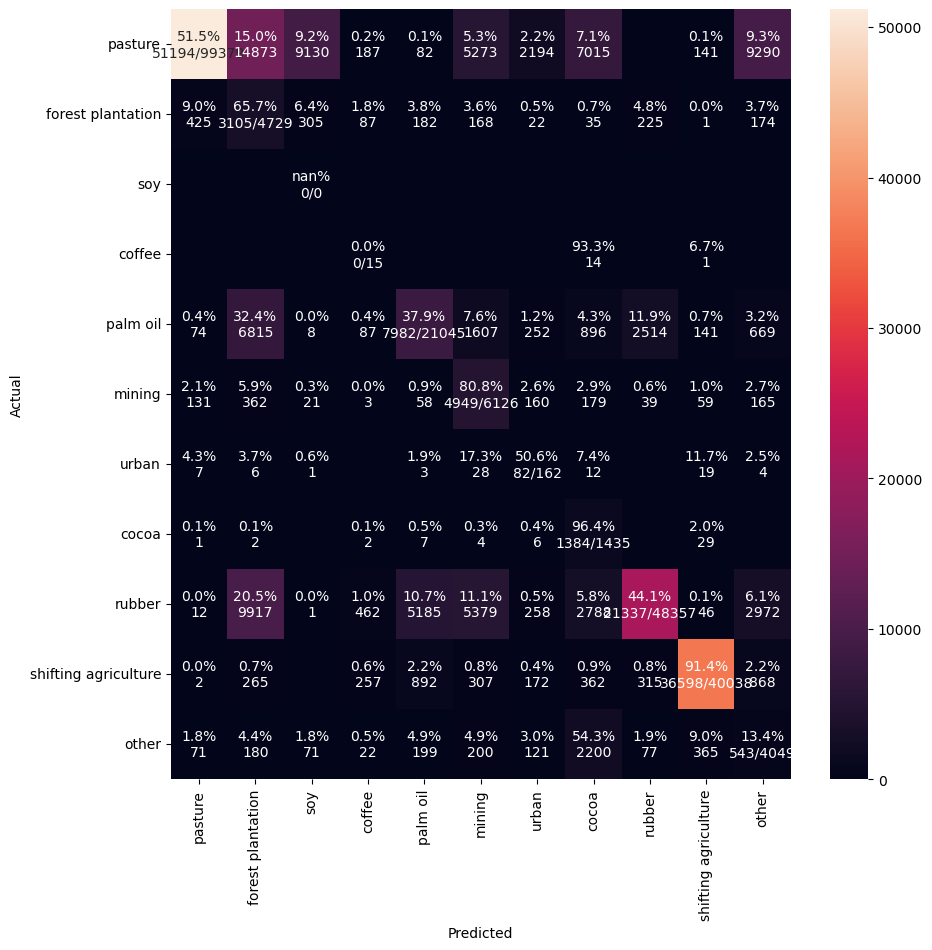

In [64]:

plot_confusion_matrix(df.driver.tolist(), df[wandb_id_to_eval].tolist())

/tmp/ipykernel_196543/4075897149.py:21: RuntimeWarning: invalid value encountered in divide
  cm_perc = cm / cm_sum.astype(float) * 100
/tmp/ipykernel_196543/4075897149.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)


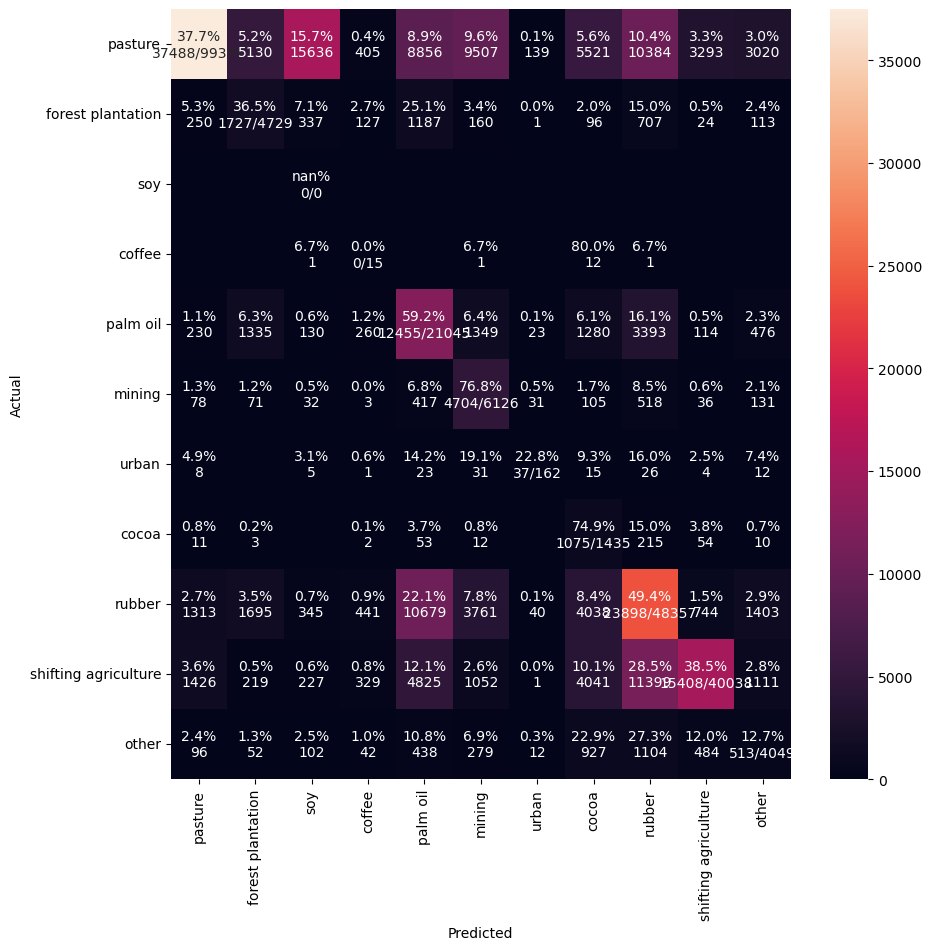

In [70]:

plot_confusion_matrix(df.driver.tolist(), df['wyfrp4uy'].tolist())


In [66]:
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)




In [67]:
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)
pd.DataFrame(metrics)

,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.092980,0.0,0.087403,0.276249,0.036977,0.547087,0.986074,0.870649,0.978556,0.0,0.025099,0.564377,0.354643,0.857314
recall,0.964460,0.0,0.656587,0.807868,0.134107,0.379282,0.515139,0.441239,0.914082,0.0,0.506173,0.564377,0.483540,0.564377
f1-score,0.169608,0.0,0.154270,0.411713,0.057969,0.447987,0.676740,0.585666,0.945221,0.0,0.047827,0.564377,0.317909,0.650520
support,1435.000000,15.0,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.564377,225335.000000,225335.000000


In [73]:
metrics = classification_report(df.driver.tolist(), df[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0)




In [74]:
pd.DataFrame(metrics)

,cocoa,coffee,forest plantation,mining,other,palm oil,pasture,rubber,shifting agriculture,soy,urban,accuracy,macro avg,weighted avg
precision,0.062829,0.0,0.168784,0.225547,0.075563,0.319909,0.916577,0.462736,0.764248,0.0,0.130282,0.431824,0.284225,0.680736
recall,0.749129,0.0,0.365193,0.767875,0.126698,0.591827,0.377223,0.494199,0.384834,0.0,0.228395,0.431824,0.371398,0.431824
f1-score,0.115934,0.0,0.230867,0.348677,0.094667,0.415319,0.534478,0.477950,0.511902,0.0,0.165919,0.431824,0.263247,0.484915
support,1435.000000,15.0,4729.000000,6126.000000,4049.000000,21045.000000,99379.000000,48357.000000,40038.000000,0.0,162.000000,0.431824,225335.000000,225335.000000


In [124]:
#df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
gdf = gpd.GeoDataFrame(df)

In [125]:
gdf.to_file('/home/jan/Documents/EPFL/Picterra/localito/data/misc/preds_2021_with_project2_code_v2.gpkg')

### Get metrics per dataset

In [80]:
df.columns

Index(['geometry', 'mines', 'rubber', 'palm_oil_2021', 'masolele_africa',
       'mapbiomas_venezuela', 'mapbiomas_brasil', 'cotedivoire', 'cocoa',
       'mapbiomas_indonesia', 'mapbiomas_peru', 'mapbiomas_bolivia',
       'mapbiomas_paraguay', 'label', 'original_label', 'dataset', 'sampleid',
       'split', 'driver', 'f469bwyp', 'wyfrp4uy'],
      dtype='object')

In [81]:
label_datasets = ['mines', 'rubber', 'palm_oil_2021', 'masolele_africa',
       'mapbiomas_venezuela', 'mapbiomas_brasil', 'cotedivoire', 'cocoa',
       'mapbiomas_indonesia', 'mapbiomas_peru', 'mapbiomas_bolivia',
       'mapbiomas_paraguay']

In [92]:
wandb_id_to_eval = 'f469bwyp'

for dst in label_datasets:
    print(dst)
    subset = df.loc[~df[dst].isna()]
    metrics = pd.DataFrame(classification_report(subset.driver.tolist(), subset[wandb_id_to_eval].tolist(), output_dict=True, zero_division=0))
    cols = [col for col in metrics.columns if not (metrics[col] == 0.0).all()]
    
    print(pd.DataFrame(metrics[cols]))
    print()
    print()

mines
                mining  accuracy    macro avg  weighted avg
precision     1.000000  0.834992     0.090909      1.000000
recall        0.834992  0.834992     0.075908      0.834992
f1-score      0.910077  0.834992     0.082734      0.910077
support    4824.000000  0.834992  4824.000000   4824.000000


rubber
                 rubber  accuracy     macro avg  weighted avg
precision      1.000000   0.47073      0.125000      1.000000
recall         0.470730   0.47073      0.058841      0.470730
f1-score       0.640131   0.47073      0.080016      0.640131
support    45234.000000   0.47073  45234.000000  45234.000000


palm_oil_2021
               palm oil  accuracy     macro avg  weighted avg
precision      1.000000  0.420461      0.090909      1.000000
recall         0.420461  0.420461      0.038224      0.420461
f1-score       0.592007  0.420461      0.053819      0.592007
support    15483.000000  0.420461  15483.000000  15483.000000


masolele_africa
                cocoa  coffee  

In [ ]:

gdf.crs = 4326
gdf['geometry'] = gdf.to_crs(3857).geometry.buffer(500, cap_style=3).to_crs(4326)

In [ ]:
'''
for dataset in datasets:
    gdf_subset = gdf.loc[gdf.intersects.dataset]
    gdf

'''